In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

## Monte Carlo

Monte Carlo - simulate thousands of possible outcomes - the analyze the distribution of outcomes 
            - it just an act/technique of collecting data of outcomes -> then analyse it (distribution, skewness, kurtosis, VaR, percentile)

## Geometric Brownian Motion

Brownian Motion - discovered by robert brown 
                - he watch pollen move randomly in water (pollen moves randomly but starts from current position)
                - drunk man analogy
                    - start walking -> random step -> random step -> random step

Geometric Brownian Motion   - apply BM to stock prices
                            - Geometric = movements are multiplicative
                            - because stock return are compound (price x (1 + changes))

Tomorrow Price = Today Price x euler^(Drift + Random Shock) 

mu = average daily return
sigma = daily volatility

Drift = mean - (std dev^ 2 / 2)
Random Shock = std dev x epsilon

In [2]:
sp500 = yf.download("SPY", period="5y")["Close"]["SPY"]
sp500_returns = sp500.pct_change(fill_method=None).dropna()

[*********************100%***********************]  1 of 1 completed


In [3]:
mu = sp500_returns.mean()
sigma = sp500_returns.std()
last_price = sp500.iloc[-1]

print(f"Mean Daily Return : {mu:.4f}")
print(f"Daily Volatility  : {sp500_returns.std():.4f}")
print(f"Last Price        : ${last_price:.2f}")

Mean Daily Return : 0.0005
Daily Volatility  : 0.0108
Last Price        : $698.84


In [ ]:
n_simulations = 100000
n_days = 252
dt = 1/252  # add dt

all_simulations = []

for i in range(n_simulations):
    prices = [last_price]

    for day in range(n_days):
        drift = (mu - (sigma**2 / 2)) * dt 
        shock = sigma * np.random.normal(0,1) * np.sqrt(dt)  
        tomorrow = prices[-1] * np.exp(drift + shock)
        prices.append(tomorrow)

    all_simulations.append(prices)

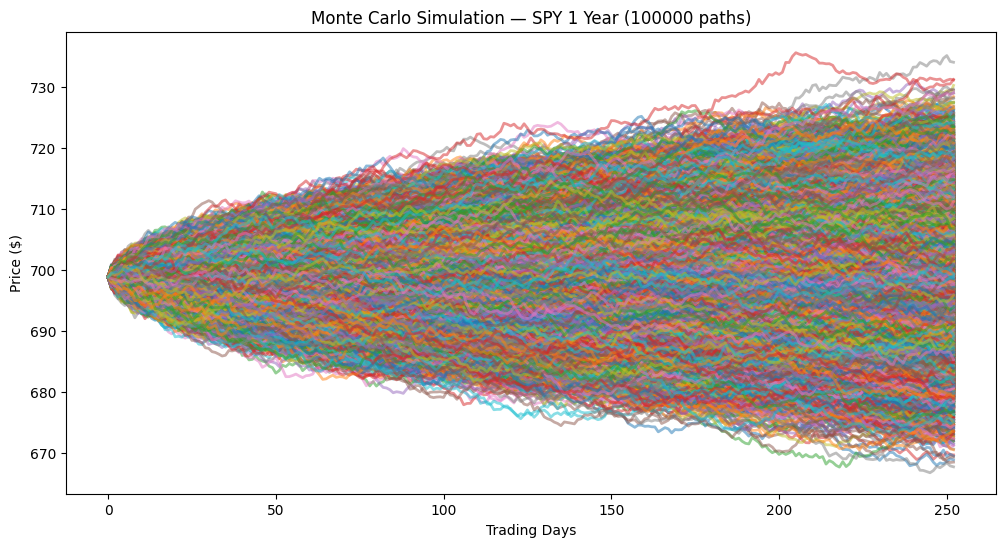

In [5]:
plt.figure(figsize=(12,6))
for path in all_simulations:
    plt.plot(path, alpha=0.5, linewidth = 2.0)

plt.title("Monte Carlo Simulation — SPY 1 Year (100000 paths)")
plt.xlabel("Trading Days")
plt.ylabel("Price ($)")
plt.show()

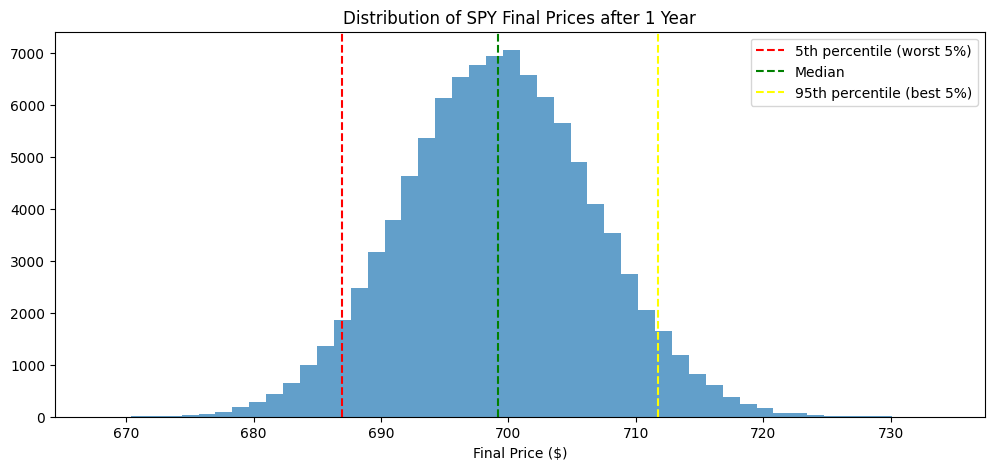

In [6]:
final_prices = [path[-1] for path in all_simulations]

#distribution
plt.figure(figsize=(12,5))
plt.hist(final_prices, bins=50, alpha=0.7)

# percentile line
plt.axvline(np.percentile(final_prices, 5), color="red", linestyle="--", label="5th percentile (worst 5%)")
plt.axvline(np.percentile(final_prices, 50), color="green", linestyle="--", label="Median")
plt.axvline(np.percentile(final_prices, 95), color="yellow", linestyle="--", label="95th percentile (best 5%)")

plt.legend()
plt.title("Distribution of SPY Final Prices after 1 Year")
plt.xlabel("Final Price ($)")
plt.show()

In [7]:
final_prices = [path[-1] for path in all_simulations]
final_prices = np.array(final_prices)

prob_loss = np.mean(final_prices < last_price) * 100

print(f"Starting Price      : ${last_price:.2f}")
print(f"Worst Case  (5%)    : ${np.percentile(final_prices, 5):.2f}")
print(f"Median      (50%)   : ${np.percentile(final_prices, 50):.2f}")
print(f"Best Case   (95%)   : ${np.percentile(final_prices, 95):.2f}")
print(f"Average Final Price : ${np.mean(final_prices):.2f}")
print(f"Probability Loss    : {prob_loss:.2f}%")

Starting Price      : $698.84
Worst Case  (5%)    : $686.93
Median      (50%)   : $699.21
Best Case   (95%)   : $711.74
Average Final Price : $699.25
Probability Loss    : 48.13%
